# COVID-19 Data Analysis, Step by Step

In this notebook we analyse real COVID-19 data the way a data analyst does it: **first understand, then clean, then answer questions.**

| Part | What we do |
|---|---|
| 1. Know the data | Read the data card. Decide the questions we want to answer. |
| 2. Load and look | Open the file and look at it from every side. |
| 3. Clean the rows | Find duplicates and rows that should not be there. |
| 4. Choose the columns | Keep only the columns that help our questions. |
| 5. Missing values | Find the empty cells and decide what to do with each. |
| 6. Outliers | Find very big or very small values and decide what to do. |
| 7. Answer the questions | Use graphs and percentages. |

Run the cells from top to bottom. Every code cell is followed by a text cell that explains what we saw.

## Part 1: Know the data

### Data card

A **data card** is the "profile" of a dataset: who made it, what one row means, and what each column means. Read it before touching the data.

| | |
|---|---|
| **Name** | OWID COVID-19 dataset |
| **Made by** | Our World in Data (OWID) |
| **Link** | https://github.com/owid/covid-19-data |
| **Licence** | Free to use if you give credit to OWID (Creative Commons BY 4.0) |
| **One row means** | One country on one day |
| **Period** | 1 Jan 2020 to 14 Aug 2024. It is no longer updated. |
| **Size** | About 429,000 rows and 67 columns |
| **Numbers come from** | Johns Hopkins University (cases, deaths), official reports (tests, vaccines), UN and World Bank (country facts) |

### The columns

There are 67 columns, but they follow a pattern. Learn the pattern and the list becomes easy.

| Column | What it tells us | How it can help us |
|---|---|---|
| `location` | Name of the country | Compare countries |
| `continent` | Continent of the country. Empty for rows that are not countries. | Group countries, and spot the rows that are not countries |
| `date` | The day | See change over time |
| `total_cases` | **Running total** of cases up to that day | Total cases of a country |
| `new_cases` | Cases reported in that period | See waves over time |
| `total_deaths`, `new_deaths` | Same, for deaths | Same |
| `..._per_million` | The same number divided by the country's population (in millions) | **Fair comparison** between big and small countries |
| `..._smoothed` | The same number as a 7-day average | Not needed: it is a copy of another column |
| `people_vaccinated_per_hundred` | Out of 100 people, how many got at least one vaccine dose | Compare vaccination |
| `population` | Number of people in the country | Understand size |
| `median_age` | The middle age of the people in the country | Does an older country have more deaths? |
| `gdp_per_capita` | Average income per person | Does a richer country have fewer deaths? |
| tests, hospital, ICU columns | Testing and hospital numbers | Only a few countries report them |
| other country facts | Smokers, diabetes, hospital beds, life expectancy and so on | Not needed for our questions |

### Be careful

1. **"Cases" means tested cases.** Many people were never tested, so the real number is higher.
2. **Countries count in different ways**, so comparisons are never perfect.
3. **`total_` columns only go up. `new_` columns are for one period.** Do not mix them.
4. **A zero in `new_cases` can mean "nothing was reported that day"**, not "no cases".

### Our questions

We decide the questions **first**. The questions tell us which columns we need and which we can ignore.

| # | Question | Columns we need |
|---|---|---|
| 1 | How many cases and deaths happened in the world? | `total_cases`, `total_deaths` |
| 2 | Which 10 countries had the most cases? | `location`, `total_cases` |
| 3 | Which continent had the biggest share of cases and deaths? | `continent` |
| 4 | Which countries were hit hardest when we compare fairly? | `total_deaths_per_million`, `population` |
| 5 | Out of 100 people who got COVID, how many died? | `total_cases`, `total_deaths` |
| 6 | How did new cases change month by month? | `date`, `new_cases` |
| 7 | Which year had the most cases? | `date`, `new_cases` |
| 8 | How did four countries compare over time? | `new_cases_per_million` |
| 9 | How many people got vaccinated? | `people_vaccinated_per_hundred` |
| 10 | Do older or richer countries have more deaths? | `median_age`, `gdp_per_capita` |

That is **14 columns** in total. We will keep these 14 and drop the rest (in Part 4).

https://owid-docs.readthedocs.io/projects/covid/en/latest/dataset.html

## Part 2: Load and look

When we get new data we do not start with graphs. We first **look**.

### Step 1: Import the libraries

`pandas` is for tables. `matplotlib` is for graphs. `numpy` is for maths.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


This optional cell only makes the graphs cleaner (light grid lines, no border on the top and right).

In [ ]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.figsize": (8, 4)})

### Step 2: Read the file

We read the file straight from the internet, so nothing needs to be downloaded. The file is big (about 98 MB), so wait up to a minute.

> **If the link does not work:** download the file in your browser, drag it into the Colab *Files* panel on the left, and use `pd.read_csv("owid-covid-data.csv")`.

We keep the original table in `df` and **never change it**. If we make a mistake later, we can always start again from `df`.

In [ ]:
url = "https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv"
df = pd.read_csv(url)

### Step 3: How big is the data?

`shape` gives (number of rows, number of columns).

In [ ]:
df.shape

(429435, 67)

About 430,000 rows and 67 columns. That is too much to read with our eyes, so we check it piece by piece.

### Step 4: Look at the first rows

`head(3)` shows the first 3 rows. The `.T` turns the table sideways, so we can see all 67 column names in one list.

In [ ]:
df.head()

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,NaN,37.75,0.5,64.83,0.51,41128772,NaN,NaN,NaN,NaN


The first rows are Afghanistan in January 2020, when nobody was measuring much yet. That is why so many cells say `NaN` (empty).

### Step 5: Column types

`info()` shows the type of every column and how many cells are **not empty**.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 429435 entries, 0 to 429434
Data columns (total 67 columns):
 #   Column                                      Non-Null Count   Dtype  
---  ------                                      --------------   -----  
 0   iso_code                                    429435 non-null  object 
 1   continent                                   402910 non-null  object 
 2   location                                    429435 non-null  object 
 3   date                                        429435 non-null  object 
 4   total_cases                                 411804 non-null  float64
 5   new_cases                                   410159 non-null  float64
 6   new_cases_smoothed                          408929 non-null  float64
 7   total_deaths                                411804 non-null  float64
 8   new_deaths                                  410608 non-null  float64
 9   new_deaths_smoothed                         409378 non-null  float64
 

- Most columns are numbers (`float64`).
- A few columns are text: `iso_code`, `continent`, `location`, `tests_units`.
- `date` is also stored as **text**. We need to turn it into a real date.
- The "non-null" numbers are very different from column to column. Some columns have many empty cells.

### Step 6: Make `date` a real date

With a real date we can sort by time, take the year or month, and draw time graphs.

In [ ]:
df["date"] = pd.to_datetime(df["date"])
df.dtypes

,0
iso_code,object
continent,object
location,object
date,datetime64[ns]
total_cases,float64
...,...
population,int64
excess_mortality_cumulative_absolute,float64
excess_mortality_cumulative,float64
excess_mortality,float64


### Step 7: Numbers summary of every numeric column

`describe()` gives count, average (mean), smallest (min), middle (50%) and biggest (max). We look at **all** numeric columns, because at this point we do not yet know which ones matter. `.T` turns it sideways so it is easy to read.

In [ ]:
df.describe()

,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,total_cases_per_million,new_cases_per_million,new_cases_smoothed_per_million,...,male_smokers,handwashing_facilities,hospital_beds_per_thousand,life_expectancy,human_development_index,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million
count,429435,4.118040e+05,4.101590e+05,4.089290e+05,4.118040e+05,410608.000000,409378.000000,411804.000000,410159.000000,408929.000000,...,243817.000000,161741.000000,290689.000000,390299.000000,319127.000000,4.294350e+05,1.341100e+04,13411.000000,13411.000000,13411.000000
mean,2022-04-21 01:06:25.463691008,7.365292e+06,8.017360e+03,8.041026e+03,8.125957e+04,71.852139,72.060828,112096.199420,122.357073,122.713852,...,33.097758,50.649390,3.106895,73.702098,0.722178,1.520336e+08,5.604765e+04,9.766431,10.925353,1772.666404
min,2020-01-01 00:00:00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,...,7.700000,1.190000,0.100000,53.280000,0.390000,4.700000e+01,-3.772610e+04,-44.230000,-95.920000,-2936.450000
25%,2021-03-05 00:00:00,6.280750e+03,0.000000e+00,0.000000e+00,4.300000e+01,0.000000,0.000000,1916.100000,0.000000,0.000000,...,22.600000,20.860000,1.300000,69.500000,0.600000,5.237980e+05,1.765000e+02,2.060000,-1.500000,116.875000
50%,2022-04-20 00:00:00,6.365300e+04,0.000000e+00,1.200000e+01,7.990000e+02,0.000000,0.000000,29145.480000,0.000000,2.790000,...,33.100000,49.540000,2.500000,75.050000,0.740000,6.336393e+06,6.815200e+03,8.130000,5.660000,1270.800000
75%,2023-06-08 00:00:00,7.582720e+05,0.000000e+00,3.132900e+02,9.574000e+03,0.000000,3.140000,156770.190000,0.000000,56.250000,...,41.500000,82.500000,4.210000,79.460000,0.830000,3.296952e+07,3.912804e+04,15.160000,15.575000,2883.025000
max,2024-08-14 00:00:00,7.758668e+08,4.423623e+07,6.319461e+06,7.057132e+06,103719.000000,14817.000000,763598.600000,241758.230000,34536.890000,...,78.100000,100.000000,13.800000,86.750000,0.960000,7.975105e+09,1.349776e+06,78.080000,378.220000,10293.520000
std,NaN,4.477582e+07,2.296649e+05,8.661611e+04,4.411901e+05,1368.322990,513.636565,162240.412405,1508.778585,559.701663,...,13.853952,31.905236,2.549168,7.387914,0.149237,6.975408e+08,1.568691e+05,12.040658,24.560706,1991.892770



- **count** is how many cells have a value. A small count means many empty cells.
- If **mean is much bigger than the middle (50%)**, a few huge values are pulling the average up.
- Check **min** and **max**. Does any number look impossible?

Two things stand out. `new_cases` has a middle value of 0 (we will find out why later). And the biggest `population` is almost 8 billion, which is the **whole world**, not a country. Something is mixed into the data.

### Step 8: Does the data cover all years?

A graph is the fastest way to see this. We count rows per year.

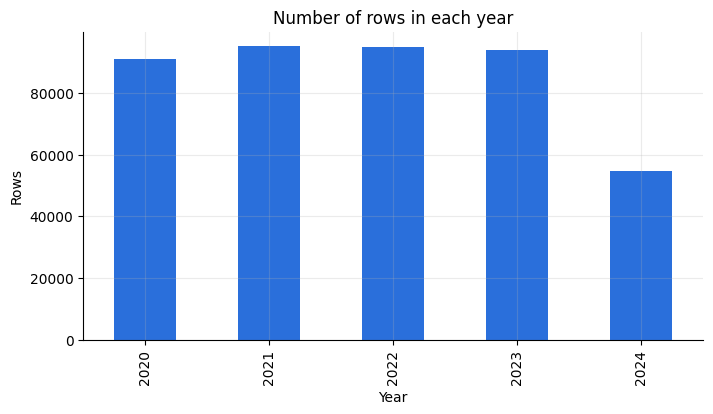

In [ ]:
df["date"].dt.year.value_counts(). sort_index().plot(kind="bar", color="#2a6fdb")
plt.title("Number of rows in each year")
plt.xlabel("Year")
plt.ylabel("Rows")
plt.show()

Every year has a similar number of rows, so there are no missing years. 2024 is shorter because the data stops in August.

## Part 3: Clean the rows

### Step 9: Are there duplicate rows?

A **duplicate row** is a row that appears more than once. We first check complete copies: rows where **every column** is the same

In [ ]:
df.duplicated().sum()

np.int64(0)

Zero. No row is a complete copy of another row. If this number was bigger than 0, we would delete the extra copies with `df.drop_duplicates()`.

But zero does not mean the data is clean. Think about what **one row** should mean: one country on one day. So the same country should appear only once on each date. Let's check that.

In [ ]:
df.duplicated(["location", "date"]). sum()

np.int64(7770)

**7,770 rows** repeat a country and a date, even though the rows are not exact copies. Where do they come from? Let's count the locations.

In [ ]:
df["location"]. nunique()

255

255 locations. The world has about 195 countries, so some rows are **not countries**. Every real country has a `continent`. Let's see which locations have an empty continent.

In [ ]:
df[df["continent"].isnull()]["location"].unique()

array(['Africa', 'Asia', 'Europe', 'European Union (27)',
       'High-income countries', 'Low-income countries',
       'Lower-middle-income countries', 'North America', 'Oceania',
       'South America', 'Upper-middle-income countries', 'World'],
      dtype=object)

Found them: `World`, the continents, the European Union and four income groups. These rows are **totals of other rows**. If we keep them, every case is counted twice (once in Pakistan and again in Asia and again in World).

We remove them. The result goes into a new table called `data`. This is the table we will work on from now on.

In [ ]:
data = df[df["continent"].notnull()].copy()
print("Countries:", data["location"].nunique())
print("Repeated country and date:", data.duplicated(["location", "date"]).sum())

Countries: 243
Repeated country and date: 1408


243 real countries, but **1,408 repeated rows are still left**. Which countries are they?

In [ ]:
repeated = data[data.duplicated(["location", "date"], keep=False)]
repeated["location"]. value_counts()

,count
location,
East Timor,2028
Faroe Islands,788


Two countries: East Timor and Faroe Islands. Let's look at one day of East Timor.

In [ ]:
day = repeated[(repeated["location"] == "East Timor") & (repeated["date"] == "2021-10-20")]
day[["location", "date", "total_cases", "total_tests"]]

,location,date,total_cases,total_tests
102790,East Timor,2021-10-20,19714.0,NaN
380925,East Timor,2021-10-20,NaN,211166.0


The same day appears twice. In the first row `total_cases` is filled and `total_tests` is empty. In the second row it is the opposite. So the two rows hold **different information**.

If we just deleted one row, we would lose information. The better way is to **join the two rows into one**. `groupby(["location", "date"]).first()` does that: for each country and date it takes the first non-empty value of each column.

In [ ]:
data = data.groupby(["location", "date"], as_index=False).first()
print("Rows now:", data.shape[0])
print("Repeated country and date:", data.duplicated(["location", "date"]).sum())

Rows now: 401502
Repeated country and date: 0


Zero repeats now.

> **Remember:** (1) First check complete duplicate rows, then check the columns that should be unique. (2) After every cleaning step, check again. One fix can show the next problem.

## Part 4: Choose the columns

We have 67 columns, but our questions need only 14. Extra columns make the work slower and confusing, so we keep only what we need.

### How do we decide? Ask four questions about every column

1. **Does it help answer one of our questions?** If not, we do not need it.
2. **Is it mostly empty?** A column that is 90% empty cannot tell us much.
3. **Is it a copy of another column?** For example `new_cases_smoothed` is just `new_cases` averaged.
4. **Do we understand it?** If we do not, we do not use it.

### Step 10: How empty is each column?

For question 2 we need the **percentage of empty cells** in each column.

In [ ]:
data.isnull().sum()

,0
location,0
date,0
iso_code,0
continent,0
total_cases,9786
...,...
population,0
excess_mortality_cumulative_absolute,388091
excess_mortality_cumulative,388091
excess_mortality,388091


Many columns are **more than 80% empty**. The ICU, hospital and excess-death columns are more than 90% empty, because only a few countries ever reported them.

### Step 11: Keep the 14 columns we need

We write the list of columns we want and select only those. All other columns are dropped.

In [ ]:
keep = ["location", "continent", "date",
        "total_cases", "new_cases", "total_deaths", "new_deaths",
        "total_cases_per_million", "new_cases_per_million", "total_deaths_per_million",
        "people_vaccinated_per_hundred", "population", "median_age", "gdp_per_capita"]

data = data[keep].copy()
data.shape

(401502, 14)

`data` now has **14 columns**. The big table `df` still has all 67, in case we ever need another column for a new question.

**Why not drop the empty columns of `keep`?** `people_vaccinated_per_hundred` is about 84% empty too, but we need it for question 9. Dropping a column is a decision about **our questions**, not only about empty cells.

## Part 5: Missing values

### Step 12: Which of our 14 columns have empty cells?

In [ ]:
print(data. isnull().sum())

location                              0
continent                             0
date                                  0
total_cases                        9786
new_cases                         11431
total_deaths                       9786
new_deaths                        10982
total_cases_per_million            9786
new_cases_per_million             11431
total_deaths_per_million           9786
people_vaccinated_per_hundred    335637
population                            0
median_age                        69537
gdp_per_capita                    75908
dtype: int64


Three groups:

- **Almost nothing missing (about 2 to 3%):** the case and death columns.
- **A lot missing (17 to 19%):** `median_age` and `gdp_per_capita`. Some countries have no value.
- **Mostly missing (84%):** `people_vaccinated_per_hundred`.

### Step 13: Why is it missing?

Before filling anything we ask **why** it is empty. Take the vaccination column: is it empty because of a mistake, or for another reason? We check the percentage of empty cells **in each year**.

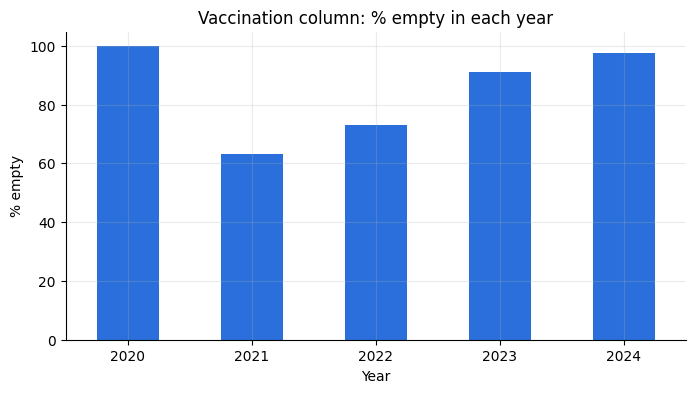

In [ ]:
data["year"] = data["date"].dt.year
data["vaccine_missing"] = data["people_vaccinated_per_hundred"].isnull()
empty_by_year = data.groupby("year")["vaccine_missing"].mean() * 100
empty_by_year.plot(kind="bar", color="#2a6fdb")
plt.title("Vaccination column: % empty in each year")
plt.xlabel("Year")
plt.ylabel("% empty")
plt.xticks(rotation=0)
plt.show()

In 2020, 100% is empty. This is not a mistake: **vaccines did not exist yet**. In 2023 and 2024 it is empty again because countries stopped reporting.

So empty does not always mean "bad data". The reason decides what we do.

### Step 14: Which filling method to use?

| Situation | What to do | How to know |
|---|---|---|
| Number column, histogram looks like a **bell** (balanced) | Fill with the **mean** | Histogram is balanced, `skew()` is close to 0 |
| Number column, histogram has a **long tail** on one side | Fill with the **median** | `skew()` is far from 0 (above 1 or below -1) |
| Text column | Fill with the **mode** (the most common value) | Highest bar in a bar chart |
| Running total (`total_...`) | **Copy the last known value** down | It only goes up, so yesterday's value is the best guess |
| A count of new things (`new_...`) | Fill with **0** | Empty means nothing was reported |
| Mostly empty (more than about 50%) | **Do not fill** | We would be inventing most of the column |

Let's look at the two number columns with 17 to 19% missing. A histogram shows how the values are spread.

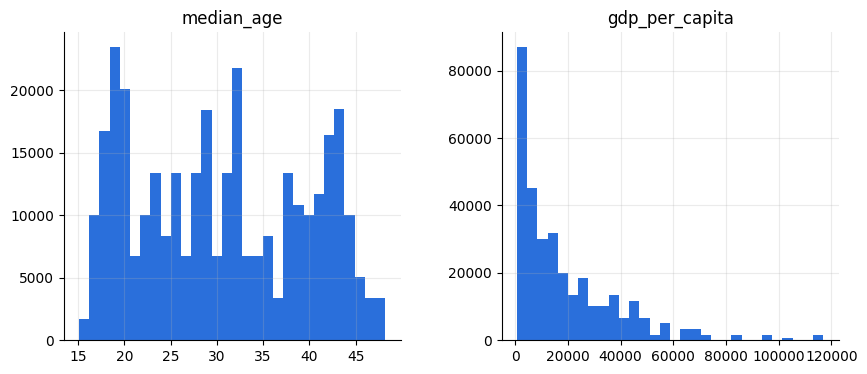

,0
median_age,0.118636
gdp_per_capita,1.830232


In [ ]:
data[["median_age", "gdp_per_capita"]].hist(bins=30, figsize=(10, 4), color="#2a6fdb")
plt.show()
data[["median_age", "gdp_per_capita"]].skew()

- `median_age` looks like a **bell** and its skew is near 0 (0.1). So we fill with the **mean**.
- `gdp_per_capita` has a **long tail on the right** (a few very rich countries) and its skew is 1.8. The mean would be pulled up by the rich countries, so we fill with the **median**.

For a text column we use a bar chart. Our only text column with a chance of being empty is `continent`. Let's see how many rows each continent has.

`continent` has no empty cells, so there is nothing to fill. If it had, the **highest bar** (Africa) is the mode, and we would use it.

### Step 15: Fill the empty cells

Running totals: copy the last known value of the **same country** down (`ffill`). Anything still empty is from before the first case, so it becomes 0.

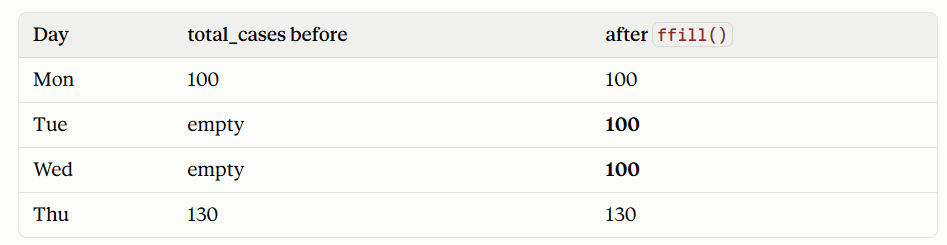

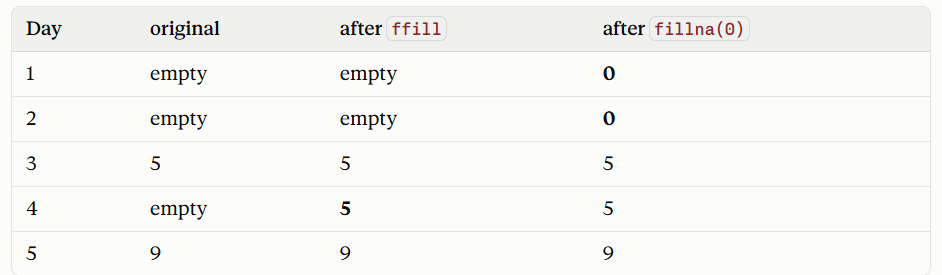

In [ ]:
total_columns = ["total_cases", "total_deaths", "total_cases_per_million", "total_deaths_per_million"]

for col in total_columns:
    data[col] = data.groupby("location")[col].ffill()
    data[col] = data[col].fillna(0)

Counts of new things: fill with 0.

In [ ]:
new_columns = ["new_cases", "new_deaths", "new_cases_per_million"]
data[new_columns] = data[new_columns].fillna(0)

Country facts: mean for `median_age` (bell shape), median for `gdp_per_capita` (long tail).

In [ ]:
data["median_age"] = data["median_age"].fillna(data["median_age"].mean())
data["gdp_per_capita"] = data["gdp_per_capita"].fillna(data["gdp_per_capita"].median())

We do **not** fill `people_vaccinated_per_hundred`, because it is 84% empty and the empty cells have real reasons. Now check again.

In [ ]:
(data.isnull().sum() / len(data) * 100).round(1)

,0
location,0.0
continent,0.0
date,0.0
total_cases,0.0
new_cases,0.0
total_deaths,0.0
new_deaths,0.0
total_cases_per_million,0.0
new_cases_per_million,0.0
total_deaths_per_million,0.0


Everything is 0% empty except the vaccination column, which we left on purpose.

### Step 16: A warning about zeros

Earlier we saw that the middle value of `new_cases` is 0. Let's look at Pakistan for two months in 2021.

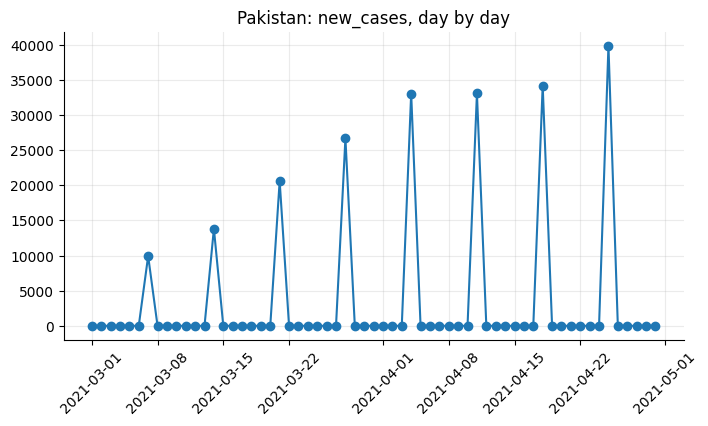

In [ ]:
pakistan = data[(data["location"] == "Pakistan") & (data["date"] >= "2021-03-01") & (data["date"] < "2021-05-01")]
plt.plot(pakistan["date"], pakistan["new_cases"], marker="o")
plt.title("Pakistan: new_cases, day by day")
plt.xticks(rotation=45)
plt.show()

## Part 6: Outliers

An **outlier** is a value that is very far from all the others. Example: in a class where everyone scores 40 to 60, one student scores 100.

An outlier is **not always a mistake**. We ask two questions:

1. Is the value **impossible**? (For example, 130% of people vaccinated.) Then it is an error and we fix it.
2. Is the value **real but extreme**? (For example, a huge outbreak.) Then we usually keep it.

### Step 17: Make a table with one row per country

Daily numbers are confusing for outliers, so we make a small table with **one row per country**. For the running-total columns the biggest value is the final total. For the country facts (population, age, gdp) every row of a country has the same value, so the biggest is that value.

In [ ]:
print(df['median_age'])

0         18.6
1         18.6
2         18.6
3         18.6
4         18.6
          ... 
429430    19.6
429431    19.6
429432    19.6
429433    19.6
429434    19.6
Name: median_age, Length: 429435, dtype: float64


In [ ]:
print(df['gdp_per_capita'])

0         1803.99
1         1803.99
2         1803.99
3         1803.99
4         1803.99
           ...   
429430    1899.78
429431    1899.78
429432    1899.78
429433    1899.78
429434    1899.78
Name: gdp_per_capita, Length: 429435, dtype: float64


In [ ]:
columns = ['continent', 'total_cases', 'total_deaths', 'total_deaths_per_million',
           'people_vaccinated_per_hundred', 'population', 'median_age', 'gdp_per_capita']

country_table = data.groupby('location')[columns].max()
country_table.head()

,continent,total_cases,total_deaths,total_deaths_per_million,people_vaccinated_per_hundred,population,median_age,gdp_per_capita
location,,,,,,,,
Afghanistan,Asia,235214.0,7998.0,197.10,46.56,41128772,18.600000,1803.99
Albania,Europe,335047.0,3605.0,1274.93,47.47,2842318,38.000000,11803.43
Algeria,Africa,272139.0,6881.0,151.31,17.46,44903228,29.100000,13913.84
American Samoa,Oceania,8359.0,34.0,702.99,NaN,44295,30.492093,12294.88
Andorra,Europe,48015.0,159.0,1994.43,72.53,79843,30.492093,12294.88


Each row is one country. We will use `country_table` for outliers and for most questions.

### Step 18: Look at the spread of every number column

A **histogram** shows how values are spread. A **box plot** shows the middle half of the values as a box. Dots outside the whiskers are possible outliers.

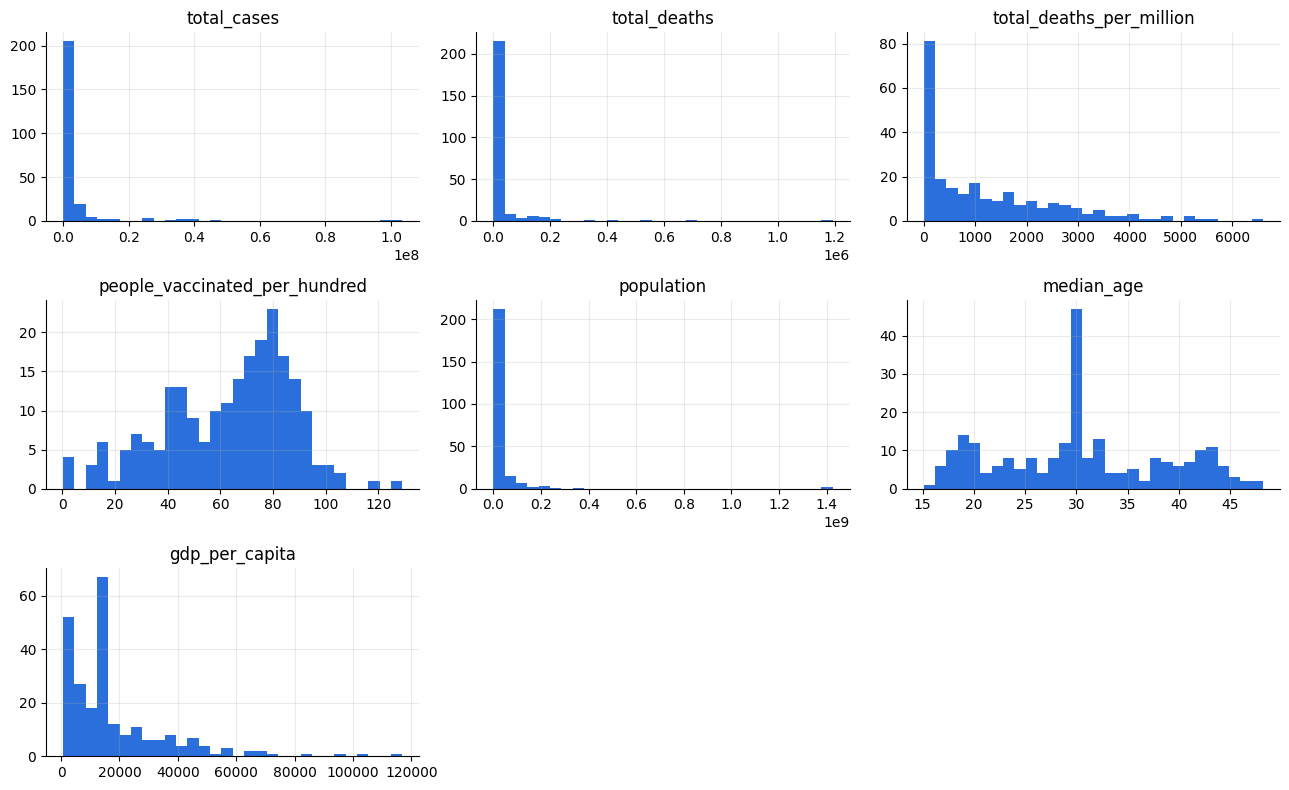

In [ ]:
numbers = country_table.drop(columns="continent")
numbers.hist(bins=30, figsize=(13, 8), color="#2a6fdb")
plt.tight_layout()
plt.show()

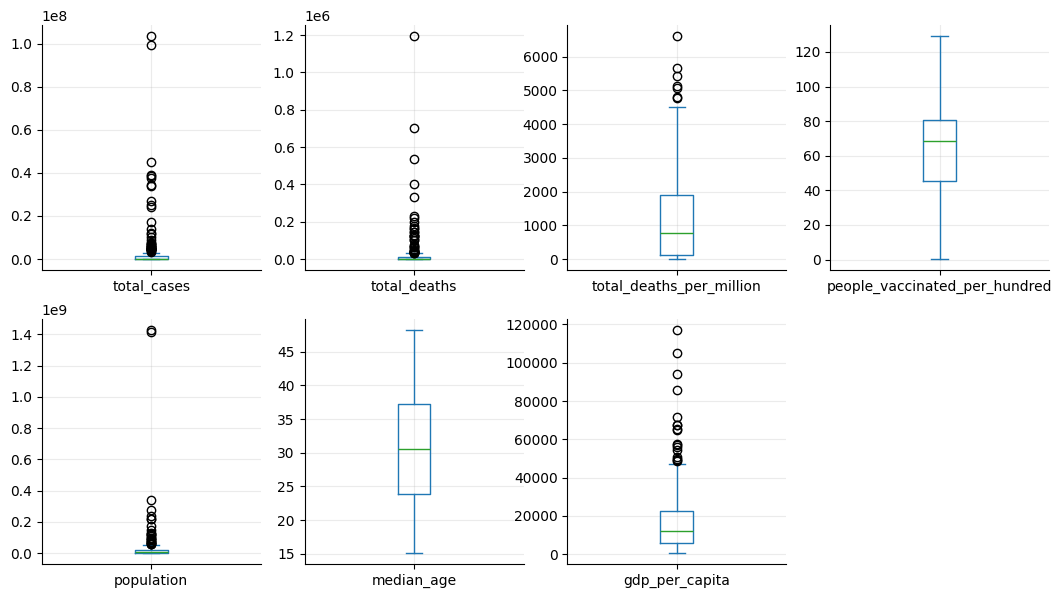

In [ ]:
numbers.plot(kind="box", subplots=True, layout=(2, 4), figsize=(13, 7))
plt.show()

What we see:

- `total_cases`, `total_deaths` and `population` have a very long tail on the right. A few countries are huge and most are small. These are real, because China and India really do have more people.
- `people_vaccinated_per_hundred` goes up to about 130 on the right. That cannot be right, because nobody can be more than 100% vaccinated (next step).
- `total_deaths_per_million` has a few dots at the top.
- `median_age` has one very tall bar at 30. Those are the countries we **filled** with the average age in Part 5. Filling many countries with the same number creates a tall bar, so remember that filling has a cost.

In [ ]:
country_table[country_table["people_vaccinated_per_hundred"] > 100][["people_vaccinated_per_hundred"]]

,people_vaccinated_per_hundred
location,
Brunei,100.48
Gibraltar,129.07
Nauru,103.27
Qatar,105.83
Tokelau,116.38
United Arab Emirates,105.83


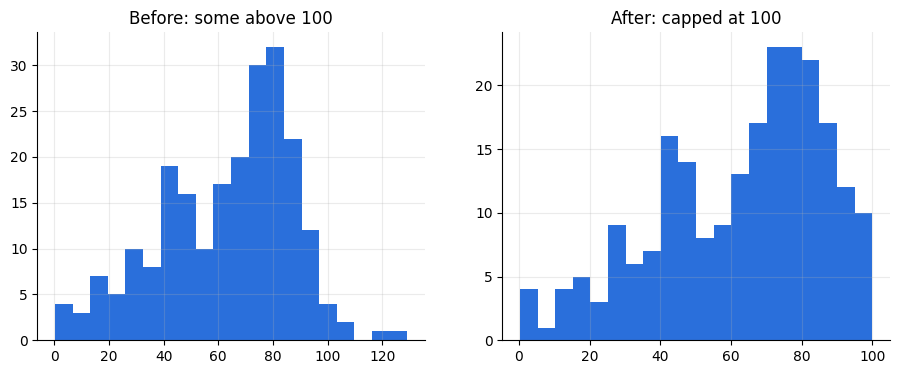

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
country_table["people_vaccinated_per_hundred"].hist(bins=20, ax=ax[0], color="#2a6fdb")
ax[0].set_title("Before: some above 100")

country_table["people_vaccinated_per_hundred"] = country_table["people_vaccinated_per_hundred"].clip(upper=100)
country_table["people_vaccinated_per_hundred"].hist(bins=20, ax=ax[1], color="#2a6fdb")
ax[1].set_title("After: capped at 100")
plt.show()

### Step 20: Extreme values that are real

Which single rows have the biggest `new_cases`?

In [ ]:
data.sort_values("new_cases", ascending=False).head(5)[["location", "date", "new_cases" ]]

,location,date,new_cases
71397,China,2022-12-25,40475477.0
71404,China,2023-01-01,24644876.0
71390,China,2022-12-18,11098550.0
71411,China,2023-01-08,8061762.0
380957,United States,2022-01-16,5650933.0


China, in December 2022 and January 2023. Let's draw China month by month.

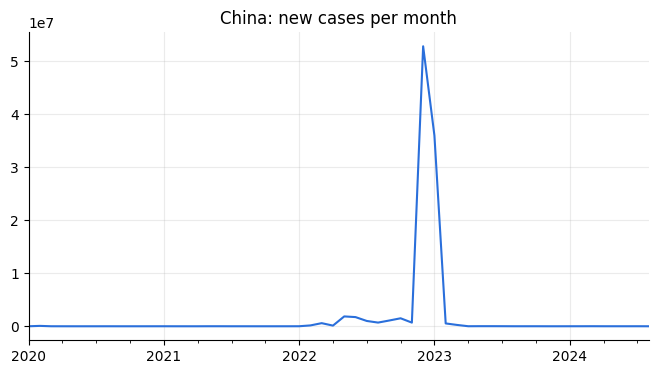

In [ ]:
data["month"] = data["date"].dt.to_period("M")
china = data[data["location"] == "China"]
china.groupby("month")["new_cases"].sum().plot(color="#2a6fdb")
plt.title("China: new cases per month")
plt.xlabel("")
plt.show()

Almost nothing for 3 years, and then a giant spike in December 2022. This is **real**: China ended its strict "zero-COVID" rules and the virus spread very fast. We keep this value, but we remember it when we read graphs later.

### Step 21: How do we find outliers with numbers?

Eyes can be fooled, so we also use rules. The most common one is the **IQR rule**:

- **Q1** is the value that 25% of countries are below. **Q3** is the value that 75% are below.
- **IQR = Q3 - Q1.** This is the width of the "box" in the box plot (the middle half of the data).
- A value is an outlier if it is **above Q3 + 1.5 x IQR** or **below Q1 - 1.5 x IQR**.

We try it on `total_deaths_per_million`.

Make the students stand in a line, from the lowest marks to the highest marks.

student 1 (lowest)------student 50---------student 100(highet)

steo 2:Find two special students
. q1= the marks of student number 25. there are 24 student with lower marks than this student, so about a quarter of the class is below.

.  Q3=the marks of student number 75. About three quarters of the class are below this student.


The students standing between student 25 and student 75 are the middle 50 students.Think of them as normal group.
Say student 25 got 45 marks and student 75 got 55 marks. So the normal group scored between 45 and 55

**IQR is the gap between those two student.**

**IQR=55-45=10**

***It tells us how spread out the normal group is.**

we say a student is an outlier if they are very far from the normal group."Very far" means more than 1.5 times the gap beyond the group:

.  1.5 *10=15
.  Above55+15=70 marks: too far avove.
.  Bolow 45-15=30 marks:too far below.

A student with 100 marks is above 70. so that student is an outlier. A student with 62 marks is not.

In [ ]:
col = country_table["total_deaths_per_million"]

q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Lower limit:", round(lower), "| Upper limit:", round(upper))

Lower limit: -2585 | Upper limit: 4601


In [ ]:
outlier = country_table[col > upper]
outlier[["total_deaths_per_million"]].round(0).sort_values("total_deaths_per_million",  ascending=False)

,total_deaths_per_million
location,
Peru,6601.0
Bulgaria,5670.0
North Macedonia,5422.0
Bosnia and Herzegovina,5115.0
Hungary,5065.0
Croatia,4800.0
Slovenia,4767.0


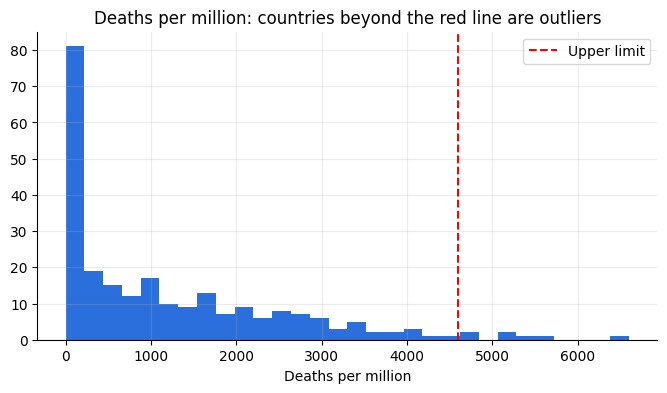

In [ ]:
col.hist(bins=30, color="#2a6fdb")
plt.axvline(upper, color="red", linestyle="--", label="Upper limit")
plt.title("Deaths per million: countries beyond the red line are outliers")
plt.xlabel("Deaths per million")
plt.legend()
plt.show()

Seven countries are beyond the red line: Peru, Bulgaria, North Macedonia, Bosnia and Herzegovina, Hungary, Croatia and Slovenia. Are they errors? **No.** They really had very high deaths for their size. We **keep** them. Deleting them would hide exactly the countries we want to study.

The two rules do not always agree. Always look at the graph too.

### Step 22: All the ways to handle outliers

There is no single right answer. You choose depending on the **reason** for the outlier. Know all of these.

**How to find outliers**

| Way | How it works |
|---|---|
| Histogram | Look for bars far away from the rest |
| Box plot | Look for dots beyond the whiskers |
| Scatter plot | Look for points far from the cloud (for two columns together) |
| IQR rule | Above Q3 + 1.5 x IQR or below Q1 - 1.5 x IQR |
| Z-score | More than 3 standard deviations from the mean |
| Common sense | Impossible values (age 200, 130%, a negative count) |

**How to handle outliers in a number column**

| Way | What we do | When to use it | Code idea |
|---|---|---|---|
| **1. Keep it** | Do nothing | The value is real and important | (nothing) |
| **2. Remove it** | Delete the rows | The value is a clear mistake, and we have plenty of data | `col[col <= upper]` |
| **3. Cap it** (clip) | Replace by the highest or lowest allowed value | We want to keep the row but limit the damage | `col.clip(upper=upper)` |
| **4. Replace it** | Replace by the median (or mean) | The value is a mistake, and we do not want to lose the row | `x[x > upper] = x.median()` |
| **5. Transform it** | Use `log` so big values shrink | Data has a long right tail and we still want every value | `np.log1p(col)` |
| **6. Put into groups** | Turn numbers into ranges (low, medium, high) | Exact values are not important | `pd.cut(col, bins)` |
| **7. Use a robust measure** | Use the median instead of the mean | We only want a summary, not to change data | `col.median()` |
| **8. Analyse separately** | Study the outliers as their own group | They are special and interesting | `country_table[col > upper]` |

**How to handle outliers in a text (category) column**

| Way | What we do | Example |
|---|---|---|
| **Fix spelling** | Join different spellings of one value | "USA", "usa" and "United States" become one |
| **Group rare values** | Join rarely used categories into "Other" | A category with only 1% of rows |
| **Remove invalid values** | Delete values that cannot exist | Gender = "Banana" |
| **Replace with the mode** | Use the most common value | A wrong value in a column with a clear favourite |
| **Keep it** | Do nothing | The rare category is real and important |

### Step 23: Try the number methods

We try five of the methods on `total_deaths_per_million` and draw them side by side.

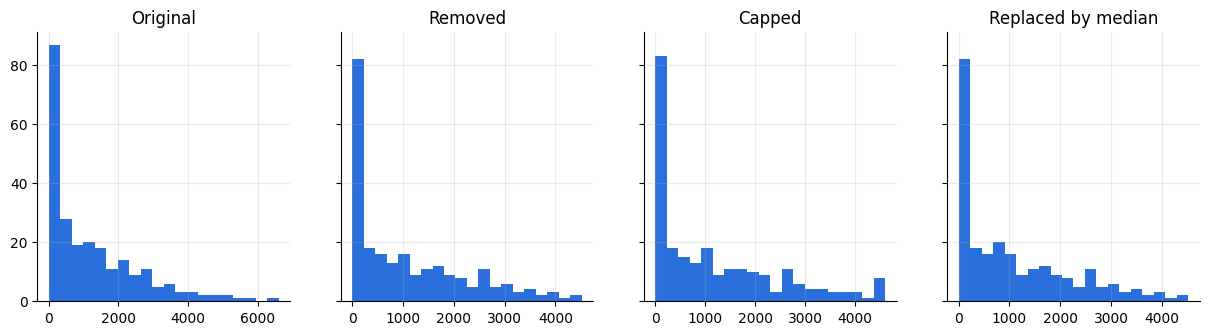

Rows left: original 243 | removed 236


In [ ]:
removed = col[col <= upper]

capped = col.clip(upper=upper)

replaced = col.copy()
replaced[replaced > upper] = col.median()

fig, ax = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)

col.hist(bins=20, ax=ax[0], color="#2a6fdb")
ax[0].set_title("Original")

removed.hist(bins=20, ax=ax[1], color="#2a6fdb")
ax[1].set_title("Removed")

capped.hist(bins=20, ax=ax[2], color="#2a6fdb")
ax[2].set_title("Capped")

replaced.hist(bins=20, ax=ax[3], color="#2a6fdb")
ax[3].set_title("Replaced by median")

plt.show()
print("Rows left: original", len(col), "| removed", len(removed))

- **Removed:** the long tail is gone, but we lost 7 countries.
- **Capped:** we still have all 243 countries, and the 7 extreme ones now sit at the limit. Notice the small bar at the right end.
- **Replaced:** the 7 countries now look like average countries, which is a lie about them.

For real data like this, none of the three is right. We keep the data as it is. But for a column with typing mistakes, one of them would be right.

**Transform** is different. We keep every value, but `log` squeezes the big ones. Let's try on `total_cases`, which is very skewed. `log1p` is a log that also works for zero.

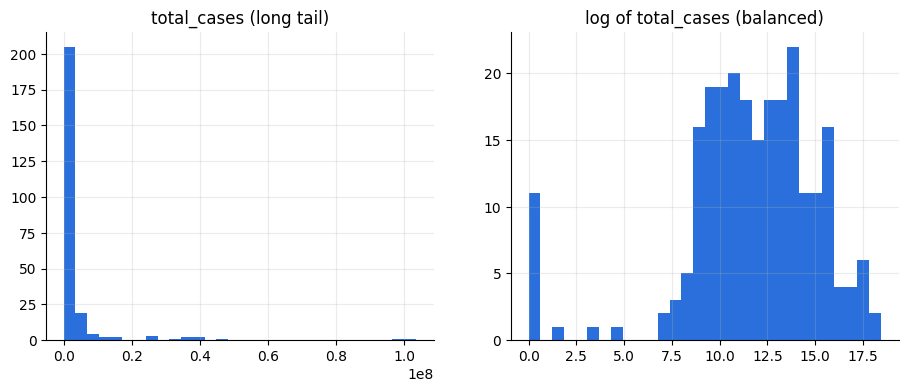

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
country_table["total_cases"].hist(bins=30, ax=ax[0], color="#2a6fdb")
ax[0].set_title("total_cases (long tail)")

np.log1p(country_table["total_cases"]).hist(bins=30, ax=ax[1], color="#2a6fdb")
ax[1].set_title("log of total_cases (balanced)")
plt.show()

After the log, the long tail turns into a bell shape. (The small bar at 0 is the countries that never reported any cases, which we filled with 0 in Part 5.) This is useful when we want to see small and big countries on the same graph.

## Part 7: Answer the questions

The data is checked and clean. Now we answer the 10 questions we wrote at the start. Each one has: **question -> code -> graph -> what it tells us.**

### Question 1: How big was the pandemic?

In [ ]:
total_cases = country_table["total_cases"].sum()
total_deaths = country_table["total_deaths"].sum()

print(f"Total cases : {total_cases:,.0f}")
print(f"Total deaths: {total_deaths:,.0f}")
print(f"Out of 100 recorded cases, {total_deaths / total_cases * 100:.1f} ended in death")

Total cases : 775,900,191
Total deaths: 7,058,885
Out of 100 recorded cases, 0.9 ended in death


About **776 million recorded cases and 7 million deaths**. About 1 in every 100 recorded cases ended in death. Remember: these are *recorded* cases.

### Question 2: Which 10 countries had the most cases?

We sort from small to large and take the last 10.

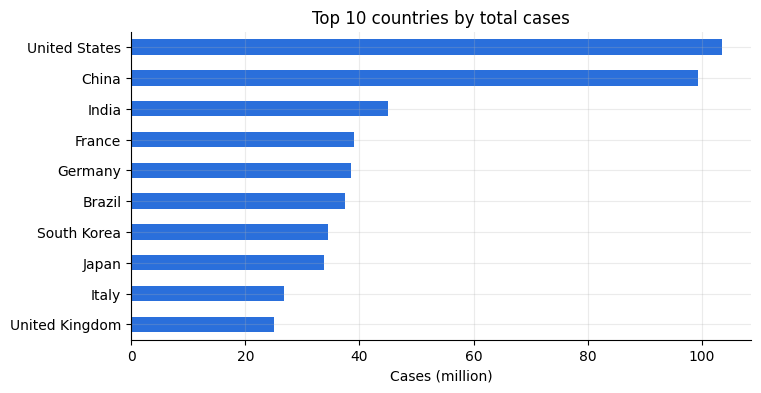

These 10 countries have 62% of all cases


In [ ]:
top10 = country_table.sort_values("total_cases").tail(10)

(top10["total_cases"] / 1_000_000).plot(kind="barh", color="#2a6fdb")
plt.title("Top 10 countries by total cases")
plt.xlabel("Cases (million)")
plt.ylabel("")
plt.show()

print(f"These 10 countries have {top10['total_cases'].sum() / total_cases * 100:.0f}% of all cases")

Ten countries out of 243 hold about **62%** of all cases. But most of them are big countries, so the next questions will check if this is fair.

### Question 3: Which continent had the biggest share of cases and deaths?

We add up by continent, and then turn the numbers into **percentages**.

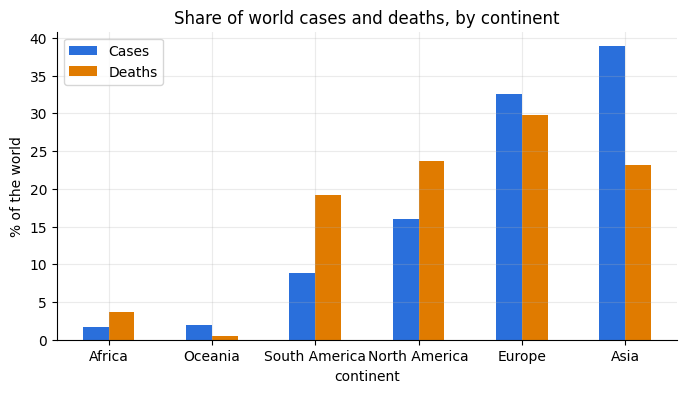

,total_cases,total_deaths
continent,,
Africa,1.7,3.7
Asia,38.9,23.2
Europe,32.6,29.8
North America,16.0,23.7
Oceania,1.9,0.5
South America,8.9,19.2


In [ ]:
by_continent = country_table.groupby("continent")[["total_cases", "total_deaths"]].sum()
percent = by_continent / by_continent.sum() * 100

percent.sort_values("total_cases").plot(kind="bar", color=["#2a6fdb", "#e07b00"])
plt.title('Share of world cases and deaths, by continent')
plt.ylabel("% of the world")
plt.xticks(rotation=0)
plt.legend(["Cases", "Deaths"])
plt.show()
percent.round(1)



Compare the blue bar and the orange bar of each continent. If **deaths are higher than cases**, that continent had more deaths for the cases it reported.

- South America: 9% of cases but 19% of deaths.
- Asia: 39% of cases but only 23% of deaths.

Part of the reason is how much each country tested. A country that tests less finds fewer cases, so its deaths look bigger compared to the cases.

### Question 4: Is it fair to compare big and small countries?

No. A country with 1.4 billion people will always have more cases than a country with 5 million. So we use **deaths per million people**. We also keep only countries with more than 1 million people, so tiny territories do not dominate.

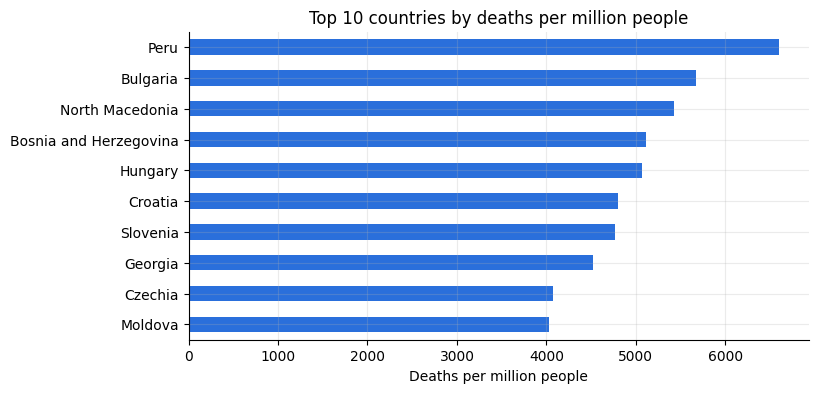

In [ ]:
big = country_table[country_table["population"] > 1_000_000]
top10_fair = big.sort_values("total_deaths_per_million").tail(10)

top10_fair["total_deaths_per_million"].plot(kind="barh", color="#2a6fdb")
plt.title("Top 10 countries by deaths per million people")
plt.xlabel("Deaths per million people")
plt.ylabel("")
plt.show()

Compare this list with Question 2. **The countries are almost completely different.** The US and India lead in raw numbers. When we divide by population, Peru and a group of Eastern European countries lead.

> A total answers "how many?". A per-person number answers "how bad was it?".

### Question 5: Out of 100 people who got COVID, how many died?

`death rate = deaths / cases x 100`. A country with very few cases gives silly numbers (3 deaths out of 10 cases is 30%). So we keep only countries with **at least 100,000 cases**. First a histogram to see the spread.

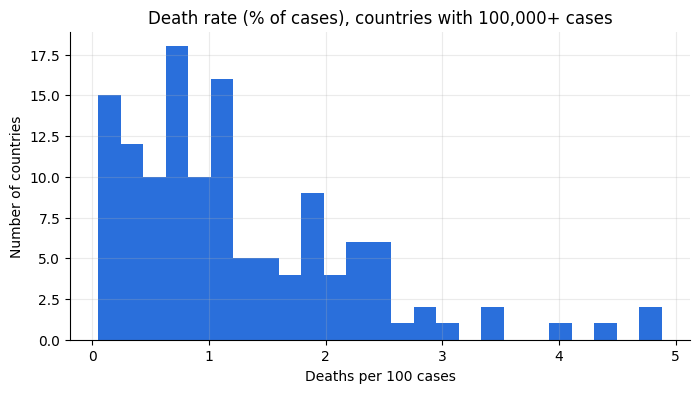

Typical (median) death rate: 1.01 %


In [ ]:
country_table["death_rate"] = country_table["total_deaths"] / country_table["total_cases"] * 100
reliable = country_table[country_table["total_cases"] >= 100_000]

reliable["death_rate"].hist(bins=25, color="#2a6fdb")
plt.title("Death rate (% of cases), countries with 100,000+ cases")
plt.xlabel("Deaths per 100 cases")
plt.ylabel("Number of countries")
plt.show()
print("Typical (median) death rate:", round(reliable["death_rate"].median(), 2), "%")

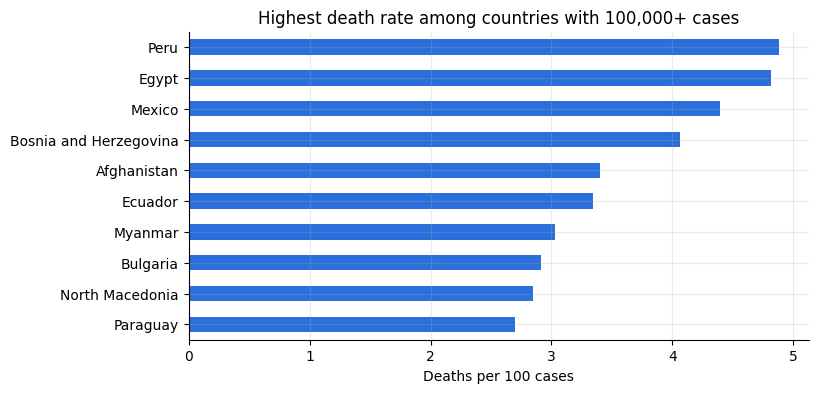

In [ ]:
top10_rate = reliable.sort_values("death_rate").tail(10)

top10_rate["death_rate"].plot(kind="barh", color="#2a6fdb")
plt.title("Highest death rate among countries with 100,000+ cases")
plt.xlabel("Deaths per 100 cases")
plt.ylabel("")
plt.show()

The typical (median) country has about 1 death per 100 cases, and most are between 0.5 and 1.8. Peru, Egypt and Mexico are the highest. A high death rate often means that **mild cases were never tested**, so the number of cases is too small. It does not always mean the illness was deadlier there.

### Question 6: How did new cases change month by month?

Remember Step 16: the daily numbers come in weekly lumps. So we add `new_cases` up **per month**. (We made the `month` column in Step 20.)

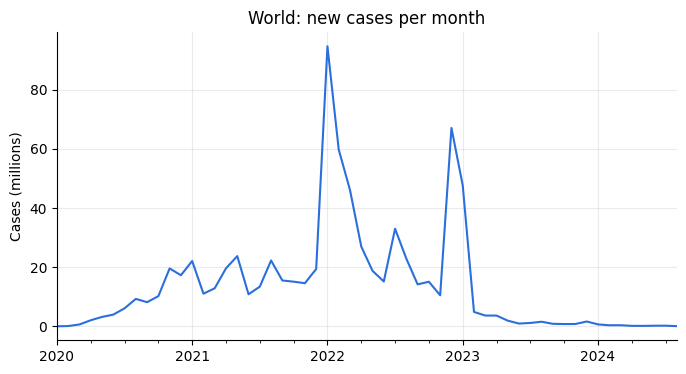

In [ ]:
monthly = data.groupby("month")["new_cases"].sum()

(monthly / 1_000_000).plot(color="#2a6fdb")
plt.title("World: new cases per month")
plt.ylabel("Cases (millions)")
plt.xlabel("")
plt.show()

We can see waves in 2020 and 2021, the **biggest wave in January 2022** (the Omicron variant), and a very tall peak at the end of 2022. That last one is the **China outbreak** we met in Step 20.

### Question 7: Which year had the most cases?

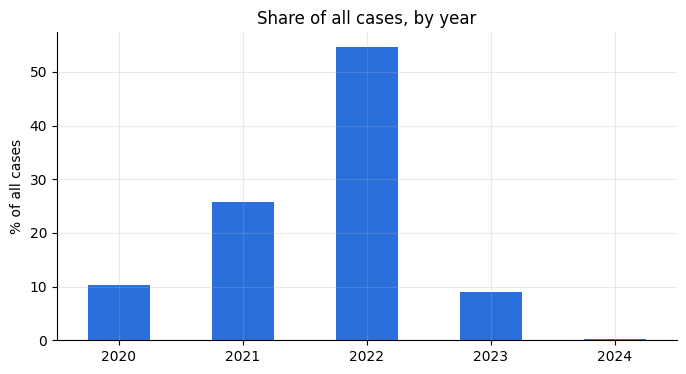

,new_cases
year,
2020,10.4
2021,25.8
2022,54.6
2023,8.9
2024,0.3


In [ ]:
yearly = data.groupby("year")["new_cases"].sum()
yearly_percent = yearly / yearly.sum() * 100

yearly_percent.plot(kind="bar", color="#2a6fdb")
plt.title("Share of all cases, by year")
plt.ylabel("% of all cases")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()
yearly_percent.round(1)

**2022 alone has more than half (55%) of all recorded cases.** But by 2022 many more people were being tested, so the real difference between the years was smaller.

### Question 8: How did four countries compare over time?

We use `new_cases_per_million`, because it is fair. `pivot_table` puts the months in rows and the countries in columns, which is the shape a line graph needs.

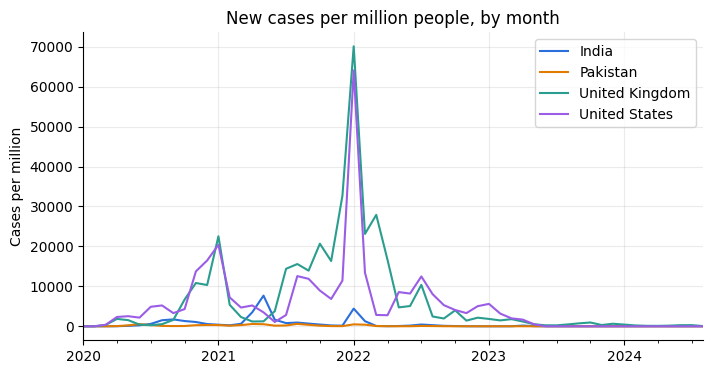

In [ ]:
four = data[data["location"].isin(["Pakistan", "India", "United States", "United Kingdom"])]
table = four.pivot_table(index="month", columns="location", values="new_cases_per_million", aggfunc="sum")

table.plot(color=["#2a6fdb", "#e07b00", "#2a9d8f", "#9b5de5"])
plt.title("New cases per million people, by month")
plt.ylabel("Cases per million")
plt.xlabel("")
plt.legend(title="")
plt.show()

The same virus, but very different lines. The UK and the US have much taller peaks than Pakistan and India. A big reason is that Pakistan and India **tested much less**, so many cases were never counted.

### Question 9: How many people were vaccinated?

First the spread: how many countries are at each level? The red line is at 70%.

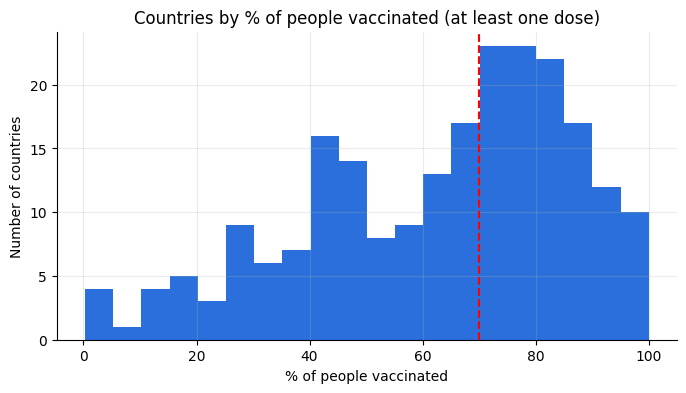

48% of countries are above 70% (223 countries have data)


In [ ]:
vaccinated = country_table["people_vaccinated_per_hundred"].dropna()

vaccinated.hist(bins=20, color="#2a6fdb")
plt.axvline(70, color="red", linestyle="--")
plt.title("Countries by % of people vaccinated (at least one dose)")
plt.xlabel("% of people vaccinated")
plt.ylabel("Number of countries")
plt.show()

print(f"{(vaccinated > 70).mean() * 100:.0f}% of countries are above 70% ({len(vaccinated)} countries have data)")

About half of the countries that have data went above 70%. `dropna()` removed the countries without data, so they are not counted as "not vaccinated".

Now by continent. We use the **median**, because a few tiny countries could pull the mean.

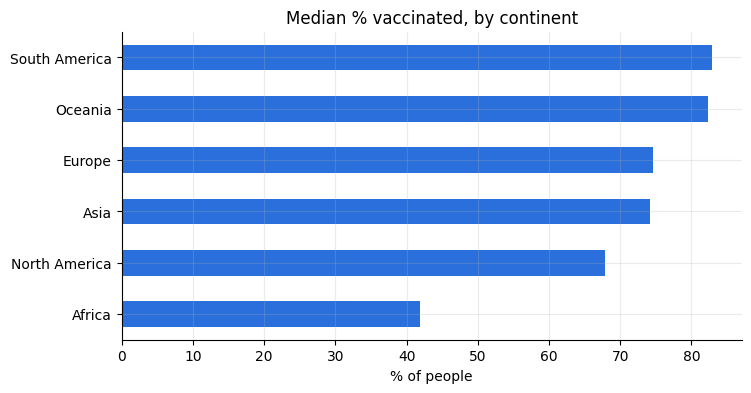

In [ ]:
by_continent = country_table.groupby("continent")["people_vaccinated_per_hundred"].median()

by_continent.sort_values().plot(kind="barh", color="#2a6fdb")
plt.title("Median % vaccinated, by continent")
plt.xlabel("% of people")
plt.ylabel("")
plt.show()

South America and Oceania are the highest (above 80%). Europe and Asia come next (about 75%). Africa is the lowest, at about 42%.

### Question 10: Do older or richer countries have more deaths?

Two number columns together need a **scatter plot**. Each dot is one country.

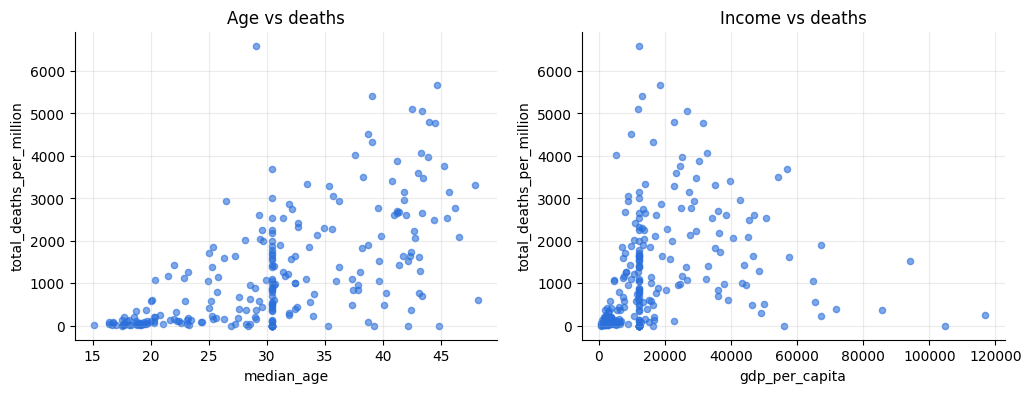

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

country_table.plot(kind="scatter", x="median_age", y="total_deaths_per_million", alpha=0.6, color="#2a6fdb", ax=ax[0])
ax[0].set_title("Age vs deaths")

country_table.plot(kind="scatter", x="gdp_per_capita", y="total_deaths_per_million", alpha=0.6, color="#2a6fdb", ax=ax[1])
ax[1].set_title("Income vs deaths")
plt.show()

Left graph: the dots go **up** from left to right. Older countries had more deaths per million. Right graph: the dots are more scattered, so income has a weaker link.

Look for the **straight vertical line of dots** in both graphs (age about 30, income about 12,000). Those are the countries whose empty values we filled with one average number in Part 5. They are not real measurements, and they weaken the pattern.

A number can tell us how strong the link is. It is called **correlation** and goes from -1 to +1. Near 0 means no link. Near +1 means "when one goes up, the other goes up".

In [ ]:
country_table[["median_age", "gdp_per_capita", "people_vaccinated_per_hundred", "total_deaths_per_million"]].corr().round(2)

,median_age,gdp_per_capita,people_vaccinated_per_hundred,total_deaths_per_million
median_age,1.00,0.58,0.48,0.62
gdp_per_capita,0.58,1.00,0.45,0.24
people_vaccinated_per_hundred,0.48,0.45,1.00,0.09
total_deaths_per_million,0.62,0.24,0.09,1.00


Look at the last column:

- `median_age` is **0.62**: a strong link. This makes sense, because the virus was most dangerous for older people. (If we ignore the countries without an age, it is 0.68. Filling lowered it a little.)
- `gdp_per_capita` is 0.24: a weak link.
- `people_vaccinated_per_hundred` is 0.09: almost no link.

Two warnings:

1. **A link is not proof of a cause.** Older countries are also richer and keep better records of deaths.
2. Vaccination shows almost no link here because "deaths per million" adds up the **whole** pandemic, including the long time before vaccines existed. So this number cannot judge vaccines.

## What we found

- The file had rows that were **not countries** (World, continents) and two countries with **repeated days**.
- Out of 67 columns, our questions needed only **14**.
- Empty cells have different reasons, so each one needed its own decision.
- Zeros in `new_cases` meant "not reported", so we added up by month.
- Big countries have the biggest totals, but **per-person numbers tell a different story**.
- 2022 had more than half of all recorded cases.
- Older countries had more deaths per million (link of 0.62).

## The steps to remember

**Know the data -> load and look -> clean the rows -> choose the columns -> missing values -> outliers -> answer the questions.**